# Adaptive FEC Demo

In [1]:
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from scipy.signal import resample_poly
from IPython.display import Audio, display

SEED = 5352  # keep random arrivals repeatable

## 1. FEC idea

![Figure 1](assets/paper_figures/figure1_repair_mechanism.png)

*French & Claypool (2001), Fig. 1.*

- Each packet carries current media plus repair data.
- The repair protects an earlier packet.
- `repair_depth` controls how far apart they are.

```text
d = 3
P0
P1
P2
P3 + repair(P0)
P4 + repair(P1)
```

A larger `d` can move the repair past a longer loss burst, but it also arrives later.

## 2. Packet format

![Figure 2](assets/paper_figures/figure2_packet_format.png)

*French & Claypool (2001), Fig. 2.*

- Header: 24 B
- Audio: 320 B
- Repair: 160 B
- Total: 504 B
- 25 packets/s = 40 ms/packet

In [2]:
HEADER = 24
PRIMARY = 320
REPAIR = 160
PKT_SIZE = 504
PKT_RATE = 25
PKT_MS = 40

## 3. Audio

The paper uses 25 packets per second, so each packet represents 40 milliseconds of audio.
Since the primary payload is 320 bytes, we choose a sample rate of 8 kilohertz and use one byte per sample.
This gives us exactly 320 bytes of audio for each packet, matching the packet format in the paper.

This is just the audio format used in this demo, not necessarily the paper's codec.

**Audio sample:** This demo uses a short speech clip from [Voice-Zero](https://github.com/OwenTyme/voice-zero/blob/main/voices/jodi_krangle.flac).


In [3]:
# load the audio sample
audio, source_sr = sf.read("assets/demo_audio.flac")

In [4]:
# resample and normalize the waveform
SR = 8000
audio = resample_poly(audio, SR, source_sr)
audio = audio / np.max(np.abs(audio))

# store each sample as one unsigned byte
audio_u8 = np.round((audio + 1) * 127.5).astype(np.uint8)

In [5]:
# pad the end so every chunk contains 320 bytes
audio_len = len(audio_u8)
pad = (-audio_len) % PRIMARY
padded = np.pad(audio_u8, (0, pad), constant_values=128)
chunks = padded.reshape(-1, PRIMARY)

print(f"Audio: {audio_len / SR:.1f} s")
print(f"Sample rate: {SR} Hz")
print(f"Packets: {len(chunks)}")

Audio: 8.5 s
Sample rate: 8000 Hz
Packets: 214


In [6]:
# convert unsigned bytes back to values an audio player can use
def to_float(samples):
    return (samples.astype(np.float32) - 128) / 128


display(Audio(to_float(audio_u8), rate=SR))

## 4. Build FEC packets

In [7]:
def make_repair(primary):
    # paper does not give the exact repair codec, so I use simple 2:1 downsampling. keep every other sample to make 160 repair bytes. 
    return primary[::2].copy()

In [8]:
def build_stream(chunks, depths):
    pkts = []

    for i, primary in enumerate(chunks):
        depth = depths[i]

        # find the earlier packet protected by this repair data
        repair_for = i - depth
        if repair_for >= 0:
            repair = make_repair(chunks[repair_for])
        else:
            # startup packets have no earlier audio to protect
            repair = np.full(REPAIR, 128, dtype=np.uint8)
            repair_for = None

        # store the packet fields
        pkt = {
            "header": bytes(HEADER),
            "primary": primary,
            "repair": repair,
            "repair_for": repair_for,
        }
        pkts.append(pkt)

    return pkts

## 5. Network setup

![Figure 3](assets/paper_figures/figure3_network_topology.png)

*French & Claypool (2001), Fig. 3.*

The paper uses:

- TCP/FTP background traffic
- an FEC/UDP stream
- a 6 Mbps bottleneck
- a 10-packet DropTail queue

This demo keeps the bottleneck and queue, but replaces the TCP flows with Poisson background traffic.

## 6. Network simulation

Each condition uses one average background rate, while Poisson arrivals keep the exact packet arrivals random.

The rates are set as 4.5, 5.7, and 6.3 Mbps. 

In [9]:
# fixed network values used by the simulator
BOTTLENECK_MBPS = 6
QUEUE_LIMIT = 10
BG_PACKET_SIZE = 1500

bg_rates = {
    "low": 4.5,
    "medium": 5.7,
    "high": 6.3,
}

In [10]:
def simulate_network(seconds, schedule):
    # set up the 1 ms simulation
    step_s = 0.001
    steps = round(seconds / step_s)
    n_pkts = round(seconds * PKT_RATE)
    pkt_step = round(1 / PKT_RATE / step_s)
    service_per_step = BOTTLENECK_MBPS * 1e6 / 8 * step_s

    # prepare the queue and result arrays
    rng = np.random.default_rng(SEED)
    queue = deque()  # each entry is [type, packet id, bytes left].
    loss_mask = np.zeros(n_pkts, dtype=bool)
    q_size = np.zeros(steps, dtype=int)
    rates = np.zeros(steps)

    for step in range(steps):
        # send queued data through the 6 mbps bottleneck
        budget = service_per_step
        while queue and budget > 0:
            sent = min(budget, queue[0][2])
            queue[0][2] -= sent
            budget -= sent
            if queue[0][2] <= 0:
                queue.popleft()

        # find the background rate for the current traffic period
        t = step * step_s
        for end, name in schedule:
            if t < end:
                rate = bg_rates[name]
                break
        rates[step] = rate

        # generate random 1500-byte background packets
        mean = rate * 1e6 / 8 / BG_PACKET_SIZE * step_s
        count = rng.poisson(mean)
        arrivals = []
        for _ in range(count):
            arrivals.append(["bg", None, BG_PACKET_SIZE])

        # add one 504-byte fec packet every 40 ms
        if step % pkt_step == 0:
            packet_id = step // pkt_step
            arrivals.append(["fec", packet_id, PKT_SIZE])

        # shuffle packets that arrive in the same ms
        rng.shuffle(arrivals)

        # use fifo droptail when packets enter the queue
        for pkt in arrivals:
            if len(queue) < QUEUE_LIMIT:
                queue.append(pkt)
            elif pkt[0] == "fec":
                loss_mask[pkt[1]] = True

        q_size[step] = len(queue)

    return {
        "loss_mask": loss_mask,
        "queue": q_size,
        "bg_rate": rates,
        "time": np.arange(steps) * step_s,
        "raw_loss": 100 * loss_mask.mean(),
    }

In [11]:
# run the same simulator under three traffic levels
seconds = len(chunks) / PKT_RATE
network = {}

for name in ["low", "medium", "high"]:
    schedule = [(seconds, name)]
    network[name] = simulate_network(seconds, schedule)
    print(f"{name.title()}: {network[name]['raw_loss']:.1f}% loss")

Low: 0.0% loss
Medium: 4.2% loss
High: 7.9% loss


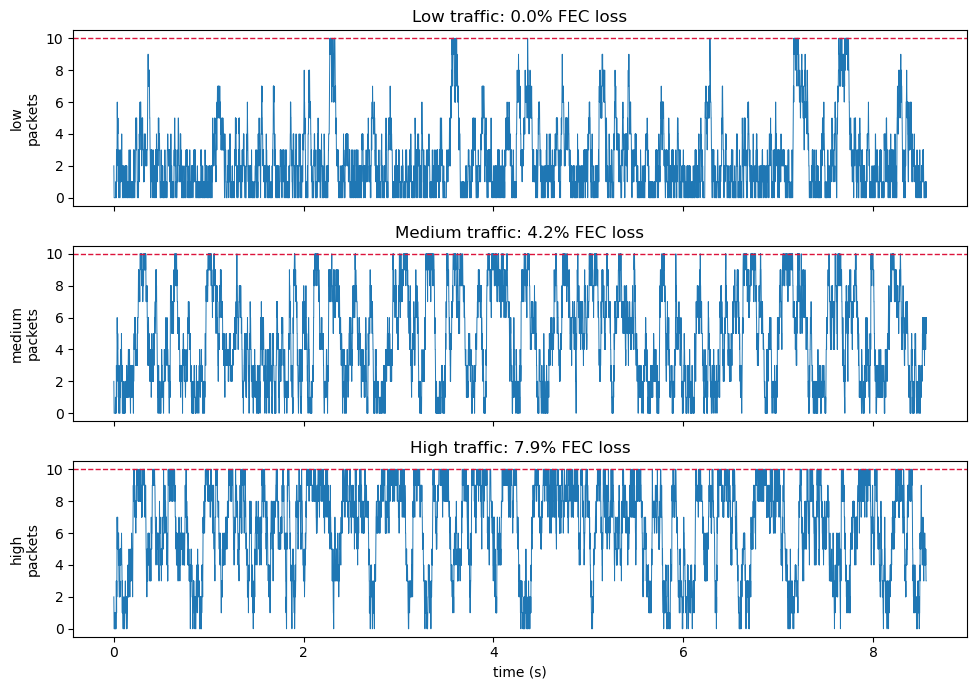

In [12]:
# plot queue occupancy for each traffic level
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
names = ["low", "medium", "high"]

for row, name in enumerate(names):
    run = network[name]
    axes[row].plot(run["time"], run["queue"], lw=0.7)
    axes[row].axhline(10, color="crimson", ls="--", lw=1)
    axes[row].set_ylabel(f"{name}\npackets")
    axes[row].set_title(f"{name.title()} traffic: {run['raw_loss']:.1f}% FEC loss")

axes[-1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

## 7. Recover packets

- Use the primary audio if it arrived.
- Otherwise, try repair data from a received packet.
- If both are missing, repeat the previous chunk as concealment.

Concealment still counts as unrepaired loss. Repair delay here means packet spacing, not full end-to-end delay.

In [13]:
def expand_repair(repair):
    # interpolate 160 repair samples back to 320 playback samples
    old_positions = np.arange(REPAIR)
    new_positions = np.linspace(0, REPAIR - 1, PRIMARY)
    expanded = np.interp(new_positions, old_positions, repair)
    return np.round(expanded).astype(np.uint8)

In [14]:
def get_metrics(states, delays, loss_mask):
    # count successful repairs and chunks that remain unrepaired
    repaired = states.count("repaired")
    unrepaired = states.count("unrepaired")

    # convert repair packet separation to ms
    if delays:
        avg_delay = np.mean(delays) * PKT_MS
    else:
        avg_delay = None

    return {
        "raw_loss": 100 * loss_mask.mean(),
        "unrepaired": 100 * unrepaired / len(states),
        "repaired": repaired,
        "avg_delay": avg_delay,
    }

In [15]:
def recover_stream(pkts, loss_mask):
    received_repairs = {}
    repair_senders = set()

    # save repairs only from packets that arrived successfully
    for sender, pkt in enumerate(pkts):
        repair_for = pkt["repair_for"]
        if not loss_mask[sender] and repair_for is not None:
            if repair_for not in received_repairs:
                received_repairs[repair_for] = (sender, pkt["repair"])
                repair_senders.add(sender)

    recovered = []
    states = []
    delays = []
    previous = np.full(PRIMARY, 128, dtype=np.uint8)

    for i, pkt in enumerate(pkts):
        # use primary audio when its packet arrived
        if not loss_mask[i]:
            audio_chunk = pkt["primary"]
            state = "primary"

        # otherwise, try repair data from a later packet
        elif i in received_repairs:
            sender, repair = received_repairs[i]
            audio_chunk = expand_repair(repair)
            state = "repaired"
            delays.append(sender - i)

        # if both lost, repeat the previous chunk
        else:
            audio_chunk = previous
            state = "unrepaired"

        recovered.append(audio_chunk)
        states.append(state)
        previous = audio_chunk

    return {
        "audio": np.concatenate(recovered)[:audio_len],
        "metrics": get_metrics(states, delays, loss_mask),
        "repair_senders": repair_senders,
    }

In [16]:
def no_fec_stream(chunks):
    # keep the same traffic, but disable repair recovery
    depths = [1] * len(chunks)
    pkts = build_stream(chunks, depths)
    for pkt in pkts:
        pkt["repair_for"] = None
    return pkts


def show_results(rows):
    print(f'{"method":<14} {"raw loss":>9} {"unrepaired":>11} {"repaired":>9} {"avg delay":>10}')

    for row in rows:
        metrics = row["result"]["metrics"]
        if metrics["avg_delay"] is None:
            delay = "--"
        else:
            delay = f'{metrics["avg_delay"]:.0f} ms'

        print(f'{row["name"]:<14} {metrics["raw_loss"]:>8.1f}% '
              f'{metrics["unrepaired"]:>10.1f}% {metrics["repaired"]:>9} {delay:>10}')

## 8. Fixed depth

A larger depth can separate primary and repair packets, but it also increases repair delay.

In [17]:
# compare fixed depths using one shared medium-traffic loss trace
fixed_loss = network["medium"]["loss_mask"]
fixed_rows = []

for d in [1, 3, 5, 7, 10]:
    depths = [d] * len(chunks)
    pkts = build_stream(chunks, depths)
    result = recover_stream(pkts, fixed_loss)
    fixed_rows.append({"name": f"d={d}", "depth": d, "result": result})

show_results(fixed_rows)

method          raw loss  unrepaired  repaired  avg delay
d=1                 4.2%        0.0%         9      40 ms
d=3                 4.2%        0.0%         9     120 ms
d=5                 4.2%        0.5%         8     200 ms
d=7                 4.2%        0.5%         8     280 ms
d=10                4.2%        0.5%         8     400 ms


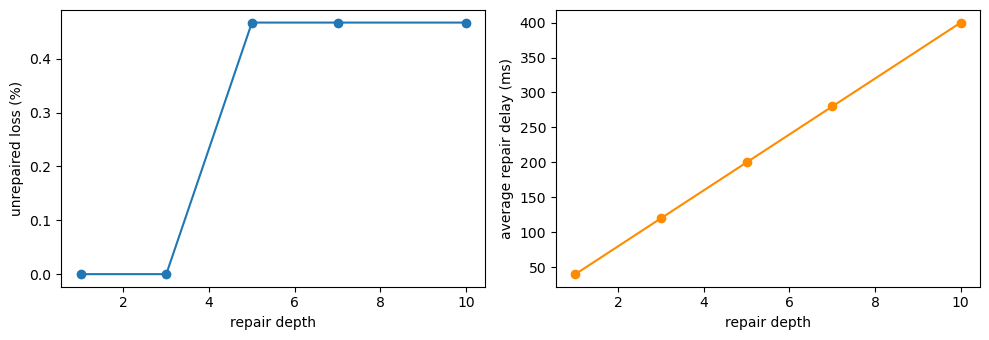

In [18]:
depths = []
unrepaired = []
delays = []

for row in fixed_rows:
    depths.append(row["depth"])
    unrepaired.append(row["result"]["metrics"]["unrepaired"])
    delays.append(row["result"]["metrics"]["avg_delay"])

# plot loss and repair delay side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(depths, unrepaired, marker="o")
axes[0].set(xlabel="repair depth", ylabel="unrepaired loss (%)")
axes[1].plot(depths, delays, marker="o", color="darkorange")
axes[1].set(xlabel="repair depth", ylabel="average repair delay (ms)")
plt.tight_layout()
plt.show()

## 9. Adaptive FEC

The adaptive rule looks at the last three completed loss bursts. It chooses a depth before seeing the current packet's outcome.

This demo assumes the sender learns previous losses immediately. Changing depth can also duplicate or skip repair coverage, which is a limitation of this simple rule.

In [19]:
def choose_depth(bursts):
    # start with the lowest delay before any burst has completed
    if not bursts:
        return 1

    # protect against the largest of the last three completed bursts
    recent = bursts[-3:]
    depth = max(recent) + 1
    return min(depth, 10)

In [20]:
def depth_schedule(loss_mask):
    bursts = []
    current_burst = 0
    depths = []

    for lost in loss_mask:
        # choose depth before observing the current packet's outcome
        depths.append(choose_depth(bursts))

        # update the current burst after making this packet's decision
        if lost:
            current_burst += 1
        elif current_burst > 0:
            bursts.append(current_burst)
            current_burst = 0

    return depths

## 10. Main comparison

Every method uses the same loss trace, so the comparison focuses on recovery and repair placement.

No FEC keeps the same 504-byte traffic but ignores repair data. Recovery is evaluated offline, so this is not a full TCP/FTP or real-time playout reproduction.

In [21]:
# generate one changing network trace for every method
changing = [(2.0, "low"), (4.0, "medium"), (6.0, "high"), (seconds, "low")]
main_run = simulate_network(seconds, changing)
loss_mask = main_run["loss_mask"]

# choose one causal repair depth for each packet
adaptive_depths = depth_schedule(loss_mask)

In [22]:
# build the no fec stream
methods = [("No FEC", no_fec_stream(chunks))]

# build the three fixed-depth streams
for depth in [1, 5, 10]:
    depths = [depth] * len(chunks)
    pkts = build_stream(chunks, depths)
    methods.append((f"Fixed d={depth}", pkts))

# build the adaptive stream
adaptive_pkts = build_stream(chunks, adaptive_depths)
methods.append(("Adaptive", adaptive_pkts))

# recover every method using the same loss trace
rows = []
for name, pkts in methods:
    result = recover_stream(pkts, loss_mask)
    rows.append({"name": name, "stream": pkts, "result": result})

show_results(rows)

method          raw loss  unrepaired  repaired  avg delay
No FEC              6.1%        6.1%         0         --
Fixed d=1           6.1%        1.9%         9      40 ms
Fixed d=5           6.1%        0.5%        12     200 ms
Fixed d=10          6.1%        0.9%        11     400 ms
Adaptive            6.1%        0.9%        11     131 ms


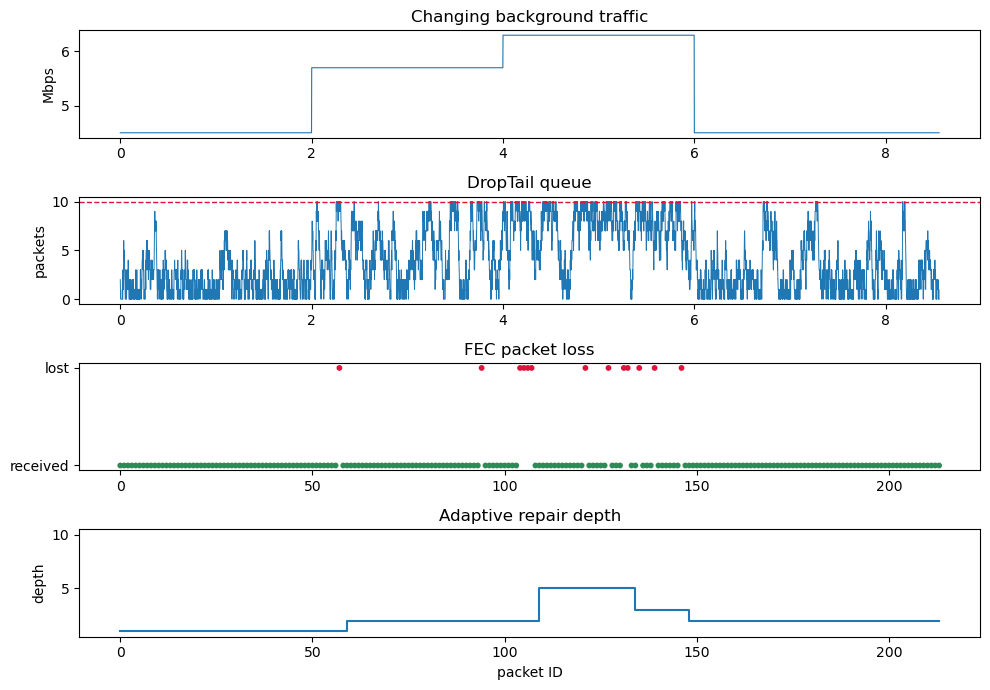

In [23]:
# show traffic, queue occupancy, packet loss, and adaptive depth
ids = np.arange(len(loss_mask))
fig, axes = plt.subplots(4, 1, figsize=(10, 7))

axes[0].plot(main_run["time"], main_run["bg_rate"], lw=0.8)
axes[0].set(title="Changing background traffic", ylabel="Mbps")

axes[1].plot(main_run["time"], main_run["queue"], lw=0.7)
axes[1].axhline(10, color="crimson", ls="--", lw=1)
axes[1].set(title="DropTail queue", ylabel="packets")

axes[2].scatter(ids, loss_mask.astype(int),
                c=np.where(loss_mask, "crimson", "seagreen"), s=10)
axes[2].set(title="FEC packet loss", yticks=[0, 1],
            yticklabels=["received", "lost"])

axes[3].step(ids, adaptive_depths, where="post")
axes[3].set(title="Adaptive repair depth", xlabel="packet ID",
            ylabel="depth", ylim=(0.5, 10.5))

plt.tight_layout()
plt.show()

In [24]:
# play the original followed by every recovered version
print("Original")
display(Audio(to_float(audio_u8), rate=SR))

for row in rows:
    print(row["name"])
    display(Audio(to_float(row["result"]["audio"]), rate=SR))

Original


No FEC


Fixed d=1


Fixed d=5


Fixed d=10


Adaptive
